In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import skew, kurtosis
from scipy.stats import chi2_contingency
import scipy.stats as stats
from scipy.stats.contingency import association
%matplotlib inline
pd.set_option('display.max_columns', None)

In [2]:
# Specify the path to the zipped file and the CSV file within it
zip_file_path = 'archive (1).zip'
csv_file_name = 'yourfile.csv'  
# Read the CSV directly from the zip file
df = pd.read_csv(zip_file_path, compression='zip')

# Part 1: Analyzing Best-Seller Trends Across Product Categories

#### Objective: Understand the relationship between product categories and their best-seller status.

- Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

- Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

- Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.


In [3]:
# General Selection
cat = df.select_dtypes(exclude="number")
num = df.select_dtypes(include="number")

# Being specific
cat_from_num = num.loc[:, num.nunique() < 20] 
cat = pd.concat([cat, cat_from_num], axis=1)
num = num.drop(columns=cat_from_num.columns)

In [4]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


- Crosstab Analysis:

Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [5]:
crosstab_result = pd.crosstab(df.category, df.isBestSeller)

In [6]:
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [7]:
crosstab_result['proportion_best_sellers'] = (crosstab_result[True] / (crosstab_result[False] + crosstab_result[True]) * 100)
crosstab_result['proportion_non_best_sellers'] = (crosstab_result[False] / (crosstab_result[False] + crosstab_result[True]) * 100)
crosstab = crosstab_result.sort_values(by='proportion_best_sellers', ascending=False)

In [8]:
crosstab

isBestSeller,False,True,proportion_best_sellers,proportion_non_best_sellers
category,,,,
Grocery,9008,556,5.813467,94.186533
Smart Home Security & Lighting,98,6,5.769231,94.230769
Health & Personal Care,9017,552,5.768628,94.231372
Mobile Phone Accessories,248,11,4.247104,95.752896
Power & Hand Tools,8353,306,3.533895,96.466105
...,...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000,100.000000
General Music-Making Accessories,259,0,0.000000,100.000000
Snowboard Boots,1449,0,0.000000,100.000000


- Statistical Tests:

Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
Compute Cramér's V to understand the strength of association between best-seller status and category.

In [9]:
# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_stats = chi2_stats, chi2_pvalue, _, _ = chi2_contingency(crosstab_result)

In [10]:
p_val = chi2_pvalue

In [11]:
crosstab_counts = crosstab_result.iloc[:, :2] 

In [12]:
cramers_v = association(crosstab_counts, method='cramer')

In [13]:
print("Chi-square Test Statistic:", chi2_stats) 
print("P-value:", p_val) 
print("Cramér's V:", cramers_v) 

Chi-square Test Statistic: 289409.14236866566
P-value: 0.0
Cramér's V: 0.1222829439760564


- Visualizations:

Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

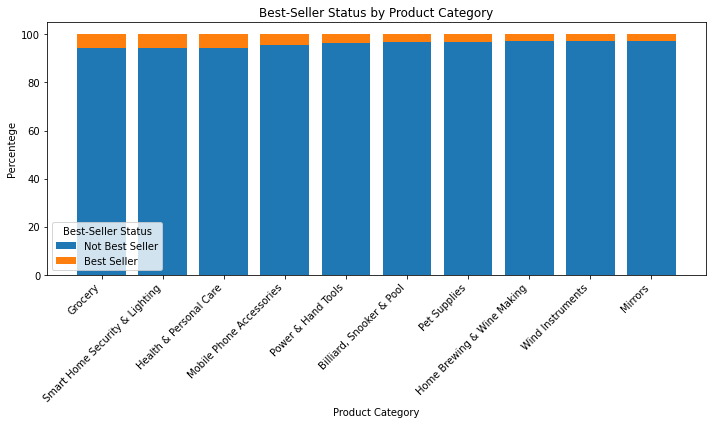

In [16]:
# Plotting a stacked bar chart to show the proportion of best-seller status by category
fig, ax = plt.subplots(figsize=(10, 6))

# Stacked bar plot
ax.bar(top10.index, top10['proportion_non_best_sellers'], label='Not Best Seller')
ax.bar(top10.index, top10['proportion_best_sellers'], bottom=top10['proportion_non_best_sellers'], label='Best Seller')

# Labeling the chart
ax.set_xlabel('Product Category')
ax.set_ylabel('Percentege')
ax.set_title('Best-Seller Status by Product Category')
ax.legend(title="Best-Seller Status")
plt.xticks(rotation=45, ha='right')

# Display the chart
plt.tight_layout()
plt.show()

In [17]:
top10 = crosstab.head(10)

In [18]:
top10

isBestSeller,False,True,proportion_best_sellers,proportion_non_best_sellers
category,,,,
Grocery,9008,556,5.813467,94.186533
Smart Home Security & Lighting,98,6,5.769231,94.230769
Health & Personal Care,9017,552,5.768628,94.231372
Mobile Phone Accessories,248,11,4.247104,95.752896
Power & Hand Tools,8353,306,3.533895,96.466105
"Billiard, Snooker & Pool",241,8,3.212851,96.787149
Pet Supplies,9152,285,3.020028,96.979972
Home Brewing & Wine Making,239,7,2.845528,97.154472
Wind Instruments,243,7,2.800000,97.200000


# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

#### Objective: Investigate how different product categories influence product prices.

- Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

-  Violin Plots:

Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.
Which product category tends to have the highest median price? Don't filter here by top categories.

- Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
Which product category commands the highest average price? Don't filter here by top categories.

- Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [20]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers, lower_bound, upper_bound

In [21]:
data_series = df['price']  # replace 'ColumnName' with your specific column
outliers, lower_bound, upper_bound = tukeys_test_outliers(data_series)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [22]:
df_sinoutliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

In [23]:
df_sinoutliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [24]:
top_20_categories = df_sinoutliers['category'].value_counts().nlargest(20).index
df_top_20 = df_sinoutliers[df_sinoutliers['category'].isin(top_20_categories)]

In [27]:
df_top_20.category.value_counts()

Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
Name: category, dtyp

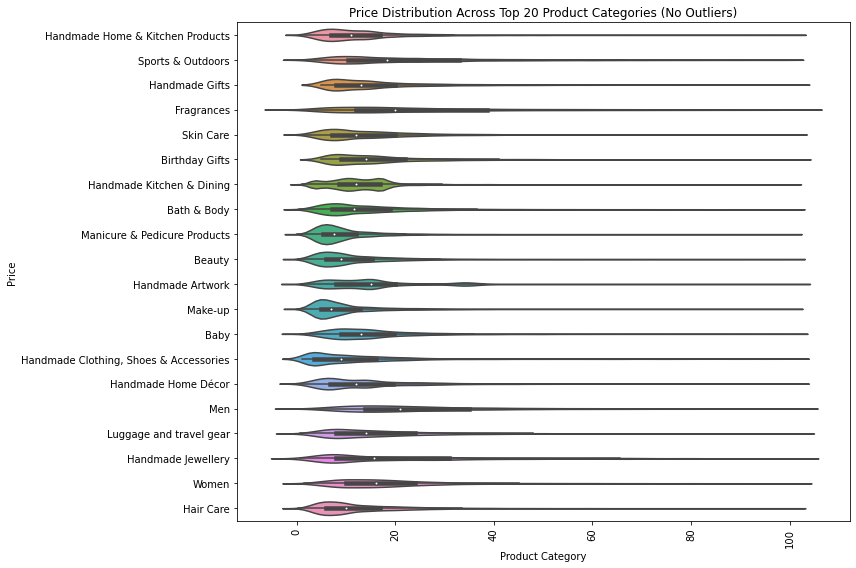

In [29]:
plt.figure(figsize=(12, 8))
sns.violinplot(data=df_top_20, x='price', y='category')
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Product Categories (No Outliers)")
plt.xlabel("Product Category")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

- Bar Charts:

Create a bar chart comparing the average price of products for the top 10 product categories (based on count). Which product category commands the highest average price? Don't filter here by top categories.

In [30]:
category_counts_t10 = df["category"].value_counts().head(10).index
top_10_df = df[df["category"].isin(category_counts_t10)]

In [32]:
bar_plot = top_10_df.groupby("category")["price"].mean().sort_values(ascending=False).reset_index()

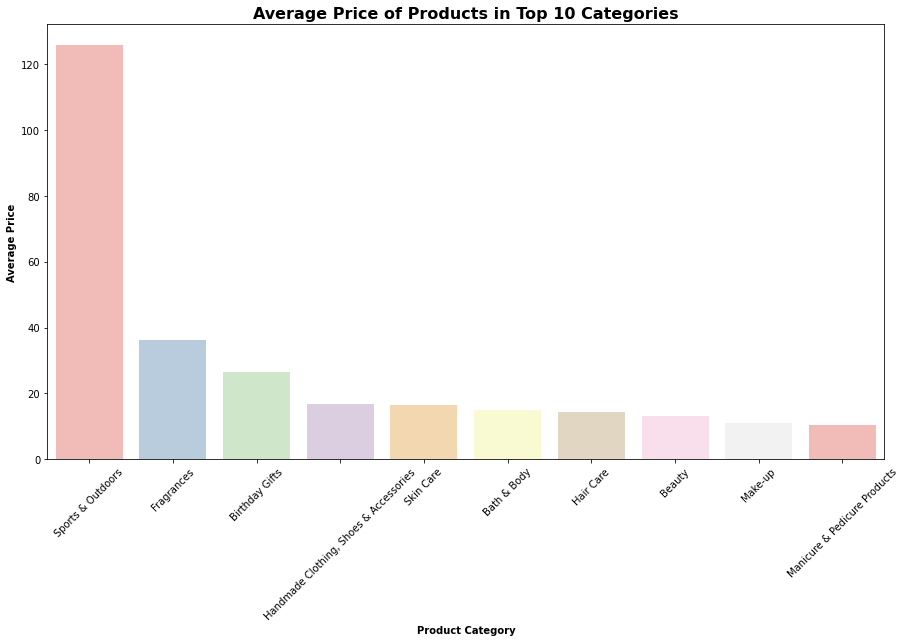

In [33]:
plt.figure(figsize=(15,8))
sns.barplot(data=bar_plot, x="category", y="price", palette="Pastel1")
plt.xlabel('Product Category', fontsize=10, weight='bold')
plt.ylabel('Average Price', fontsize=10, weight='bold')
plt.title('Average Price of Products in Top 10 Categories', fontsize=16, weight='bold')
plt.xticks(rotation=45)  # Rotate the x-axis labels for readability

plt.show()

In [34]:
bar_plot2 = df_sinoutliers.groupby("category")["price"].mean().sort_values(ascending=False).reset_index()

In [36]:
bar_plot2

,category,price
0,Motherboards,68.772432
1,Boxing Shoes,67.417803
2,Desktop PCs,66.915562
3,Tablets,66.552971
4,Graphics Cards,65.103509
...,...,...
291,Bedding Accessories,8.835220
292,Adapters,8.750197
293,Signs & Plaques,8.210513
294,Arts & Crafts,8.006540


- Box Plots:

Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

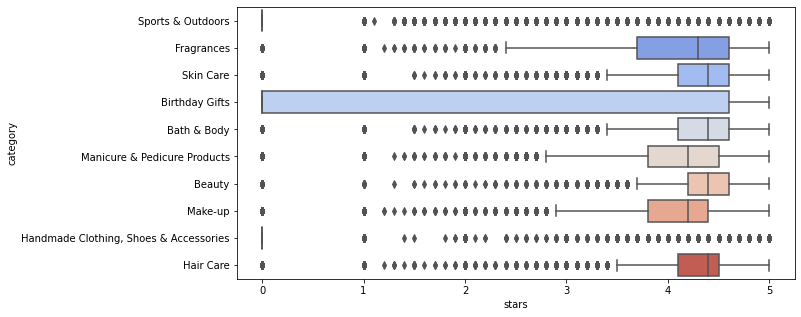

In [54]:
plt.figure(figsize=(10,5))

sns.boxplot(data=top_10_df, x="stars", y="category", palette="coolwarm") #Making this plot is difficult to see if i don't use the top 10.
plt.show()

In [38]:
#calculation:

df_sinoutliers.groupby("category")["stars"].agg("median").sort_values(ascending = False).reset_index() #not filter top categories

,category,stars
0,Computer Memory,4.7
1,Building & Construction Toys,4.6
2,Office Paper Products,4.6
3,Luxury Food & Drink,4.6
4,Kids' Play Figures,4.6
...,...,...
291,Hockey Shoes,0.0
292,Hi-Fi Receivers & Separates,0.0
293,Handmade Kitchen & Dining,0.0
294,Handmade Jewellery,0.0


# Part 3: Investigating the Interplay Between Product Prices and Ratings
#### Objective: Analyze how product ratings (stars) correlate with product prices.

- Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?

- Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.

In [58]:
crosstab_result = pd.crosstab(df['price'], df['stars'])

In [57]:
correlation_coefficient = df['price'].corr(df['stars'])
correlation_coefficient

-0.12490673262149232

In [63]:
pearson = df['price'].corr(df['stars'], method="pearson")
pearson

-0.12490673262149232

In [62]:
spearman =df['price'].corr(df['stars'], method="spearman")
spearman

-0.13316425462434212

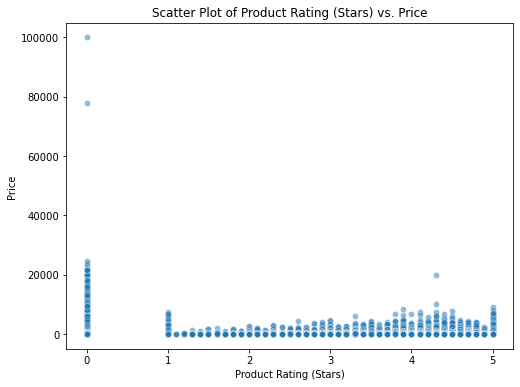

In [60]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='stars', y='price', alpha=0.5)
plt.title("Scatter Plot of Product Rating (Stars) vs. Price")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Price")
plt.show()

In [64]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


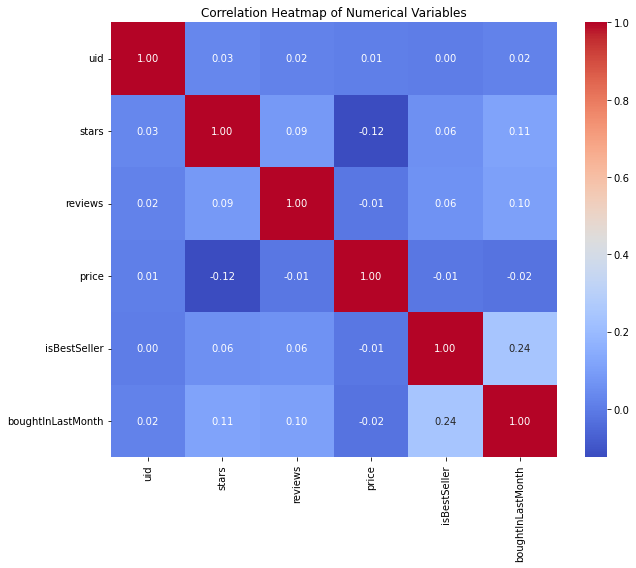

In [65]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

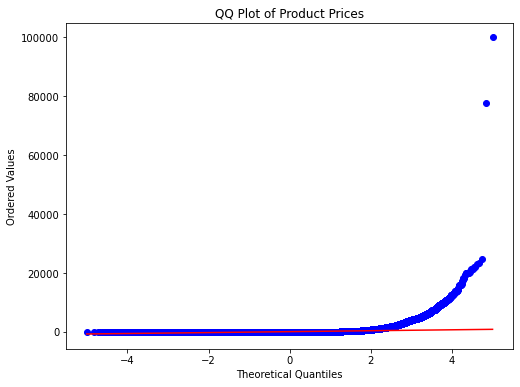

In [66]:
#Examine if product prices typically follow a normal distribution using a QQ plot.
plt.figure(figsize=(8, 6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Ordered Values")
plt.show()